Final evaluation. Choices fixed in advance using cross-validation on the training data only: HistGradientBoostingClassifier (default settings, balanced class weights), decision threshold 0.11. The model is trained once on all 60,000 training trucks and scored once on the 16,000 test trucks.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay

In [2]:
train = pd.read_csv("../data/raw/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("../data/raw/aps_failure_test_set.csv", skiprows=20, na_values="na")

X_train, y_train = train.drop(columns="class"), (train["class"] == "pos").astype(int)
X_test, y_test = test.drop(columns="class"), (test["class"] == "pos").astype(int)

model = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

p_test = model.predict_proba(X_test)[:, 1]
pred = (p_test >= 0.11).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
cost = 10 * fp + 500 * fn
print(f"Test cost: {cost}")
print(f"Caught {tp} of {tp + fn} failures; {fp} false alarms out of {tn + fp} healthy trucks")
print()
print("Benchmarks on the same test set:")
print("  Flag nothing:        187,500")
print("  Flag everything:     156,250")
print("  2016 challenge best:   9,920")

Test cost: 11040
Caught 364 of 375 failures; 554 false alarms out of 15625 healthy trucks

Benchmarks on the same test set:
  Flag nothing:        187,500
  Flag everything:     156,250
  2016 challenge best:   9,920


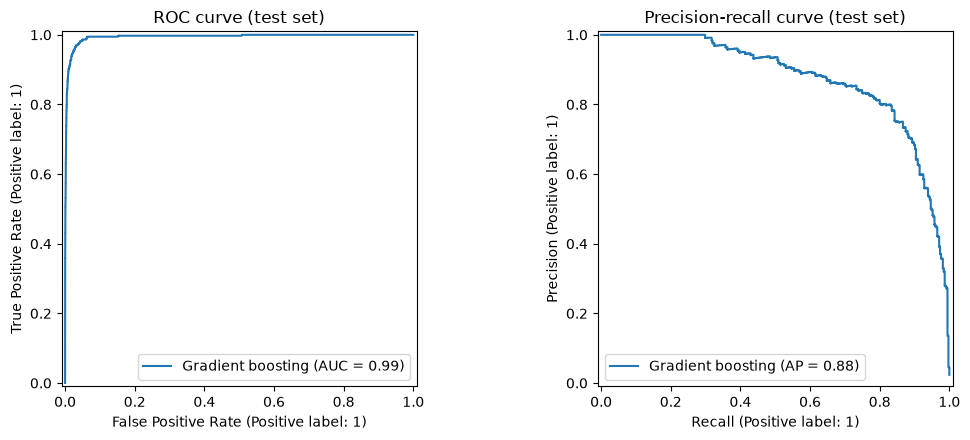

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[0], name="Gradient boosting")
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[1], name="Gradient boosting")
axes[0].set_title("ROC curve (test set)")
axes[1].set_title("Precision-recall curve (test set)")
plt.tight_layout()
plt.show()